In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
sns.set_style('whitegrid')

In [ ]:
file_path = "Concrete_Data-Sheet1.csv"
df = pd.read_csv(file_path)

# Mengubah nama kolom agar lebih ringkas dan mudah dipanggil dalam kode
column_mapping = {
    df.columns[0]: "Cement",
    df.columns[1]: "Slag",
    df.columns[2]: "FlyAsh",
    df.columns[3]: "Water",
    df.columns[4]: "Superplasticizer",
    df.columns[5]: "CoarseAgg",
    df.columns[6]: "FineAgg",
    df.columns[7]: "Age",
    df.columns[8]: "Strength",
}
df = df.rename(columns=column_mapping)

print("=== 5 BARIS PERTAMA ===")
print(df.head())

=== 5 BARIS PERTAMA ===
   Cement   Slag  FlyAsh  Water  Superplasticizer  CoarseAgg  FineAgg  Age  \
0   540.0    0.0     0.0  162.0               2.5     1040.0    676.0   28   
1   540.0    0.0     0.0  162.0               2.5     1055.0    676.0   28   
2   332.5  142.5     0.0  228.0               0.0      932.0    594.0  270   
3   332.5  142.5     0.0  228.0               0.0      932.0    594.0  365   
4   198.6  132.4     0.0  192.0               0.0      978.4    825.5  360   

   Strength  
0     79.99  
1     61.89  
2     40.27  
3     41.05  
4     44.30  



=== INFORMASI DATASET ===
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Cement            1030 non-null   float64
 1   Slag              1030 non-null   float64
 2   FlyAsh            1030 non-null   float64
 3   Water             1030 non-null   float64
 4   Superplasticizer  1030 non-null   float64
 5   CoarseAgg         1030 non-null   float64
 6   FineAgg           1030 non-null   float64
 7   Age               1030 non-null   int64  
 8   Strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB
None

=== CEK MISSING VALUES ===
Cement              0
Slag                0
FlyAsh              0
Water               0
Superplasticizer    0
CoarseAgg           0
FineAgg             0
Age                 0
Strength            0
dtype: int64

=== CEK DUPLIKAT ===
Jumlah baris duplikat: 25

=== STATISTIK DES

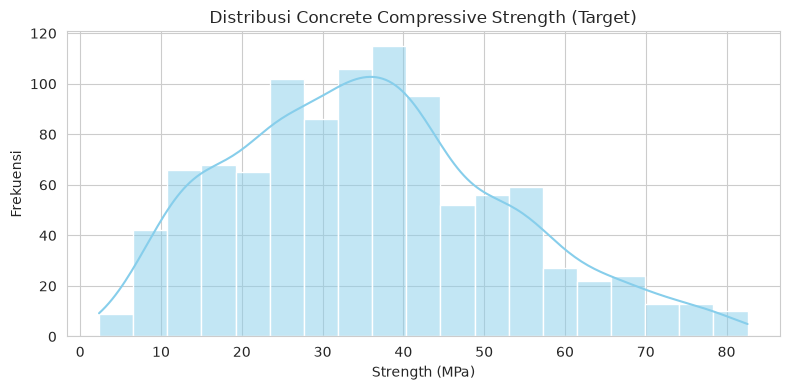

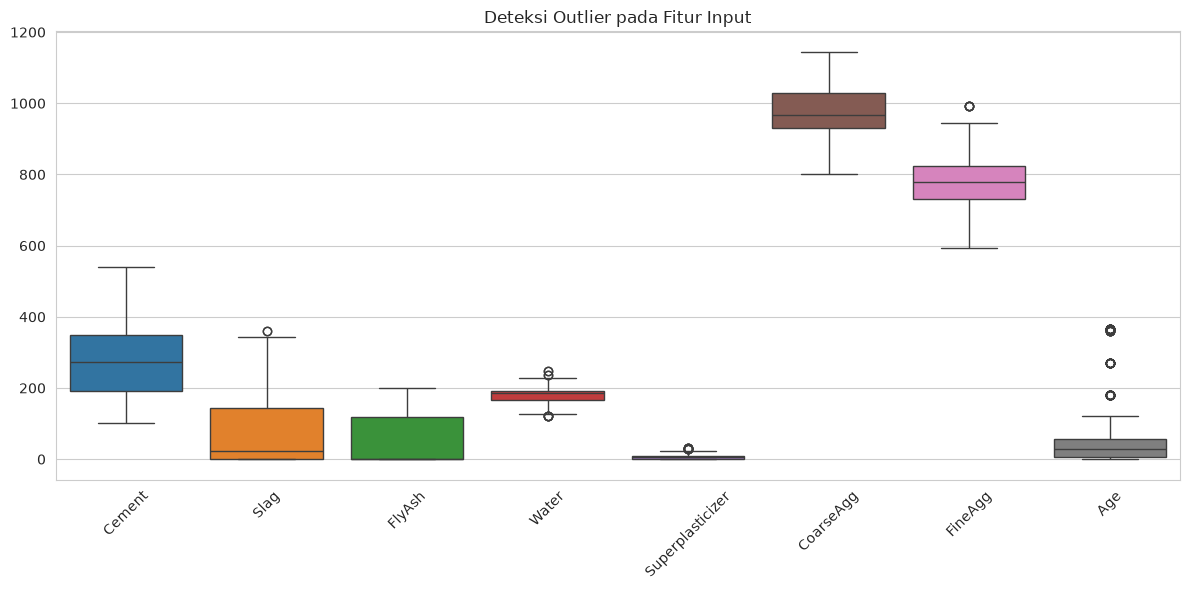

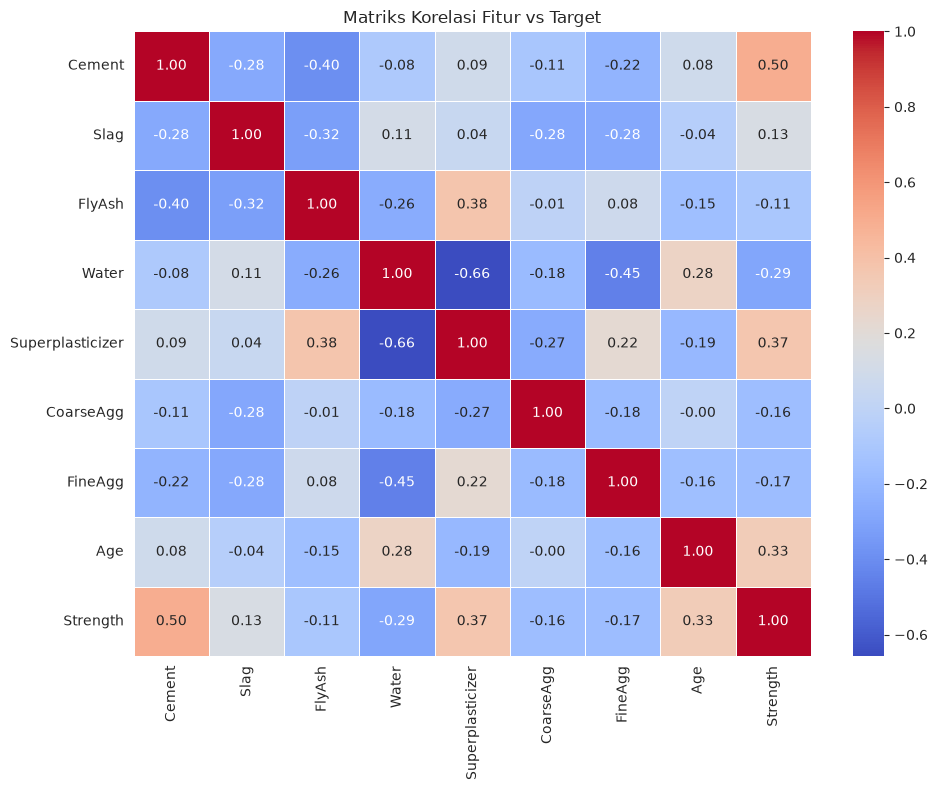

In [ ]:
print("\n=== INFORMASI DATASET ===")
print(df.info())

print("\n=== CEK MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== CEK DUPLIKAT ===")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

print("\n=== STATISTIK DESKRIPTIF ===")
print(df.describe().T)

# --- VISUALISASI 1: Distribusi Variabel Target ---
plt.figure(figsize=(8, 4))
sns.histplot(df["Strength"], kde=True, color="skyblue")
plt.title("Distribusi Concrete Compressive Strength (Target)")
plt.xlabel("Strength (MPa)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# --- VISUALISASI 2: Boxplot Fitur (Deteksi Outlier) ---
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(columns=["Strength"]))
plt.title("Deteksi Outlier pada Fitur Input")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- VISUALISASI 3: Heatmap Korelasi ---
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriks Korelasi Fitur vs Target")
plt.tight_layout()
plt.show()

In [ ]:
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(
        f"\n[Preprocessing] Duplikat dihapus. Jumlah baris sekarang: {len(df)}"
    )


[Preprocessing] Duplikat dihapus. Jumlah baris sekarang: 1005


In [ ]:
X = df.drop(columns=["Strength"])
y = df["Strength"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\n=== UKURAN PEMBAGIAN DATA ===")
print(f"Data Latih (X_train) : {X_train.shape}")
print(f"Data Uji (X_test)   : {X_test.shape}")


=== UKURAN PEMBAGIAN DATA ===
Data Latih (X_train) : (804, 8)
Data Uji (X_test)   : (201, 8)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Konversi kembali ke DataFrame agar tetap rapi
X_train_scaled_df = pd.DataFrame(
    X_train_scaled, columns=X.columns, index=X_train.index
)
X_test_scaled_df = pd.DataFrame(
    X_test_scaled, columns=X.columns, index=X_test.index
)

print("\n=== HASIL SCALING (5 Baris Pertama X_train_scaled) ===")
print(X_train_scaled_df.head())


=== HASIL SCALING (5 Baris Pertama X_train_scaled) ===
       Cement      Slag    FlyAsh     Water  Superplasticizer  CoarseAgg  \
78   2.436728 -0.837655 -0.875865 -1.872881          3.720106  -1.560059   
29   1.894731 -0.837655 -0.875865  2.132243         -1.023026  -0.525673   
280 -0.010441 -0.837655  0.638711 -0.999374          0.961689   0.016765   
507  1.519280 -0.837655 -0.875865  1.667611         -1.023026  -1.737419   
652 -1.072293  2.070419 -0.875865  0.993895         -1.023026   0.038774   

      FineAgg       Age  
78   1.487304 -0.679041  
29  -2.218565 -0.614850  
280  1.263493 -0.679041  
507 -0.664251 -0.277844  
652 -0.999350 -0.614850  
